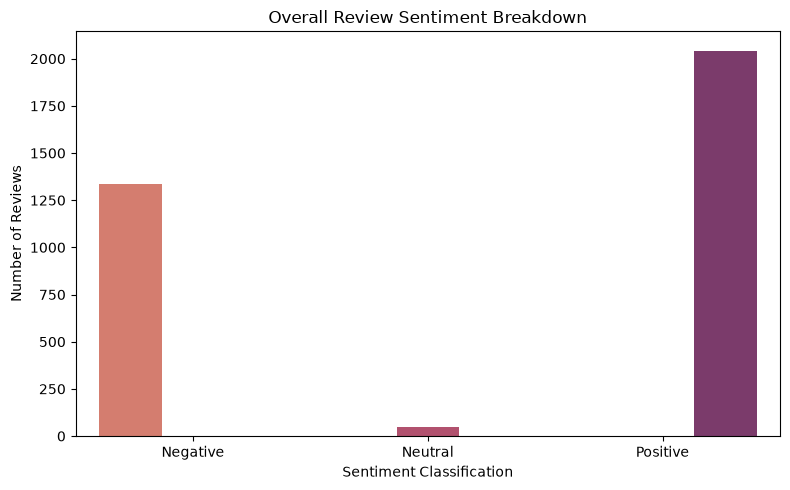

✅ Processed 3427 Customer Experience Reviews Successfully!


In [2]:
# ==========================================
# STEP 1: IMPORT NATURAL LANGUAGE AND GRAPHICS TOOLS
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
import os

# Download required lexicon reference dictionary architectures silently
nltk.download('vader_lexicon', quiet=True)
os.makedirs('../images', exist_ok=True)

# ==========================================
# STEP 2: LOAD AND FORMAT THE DOWNLOADED TEXT REVIEWS
# ==========================================
# Point precisely to your extracted Kaggle file path
df_reviews = pd.read_csv('../data/reviews_data1.csv')

# Dynamically locate text data columns within the layout structure
review_col = [col for col in df_reviews.columns if 'review' in col.lower() or 'text' in col.lower()][0]
df_reviews['clean_text'] = df_reviews[review_col].astype(str).str.lower()

# ==========================================
# STEP 3: EXECUTE SENTIMENT VALENCE SCORING
# ==========================================
# Initialize the lexicon engine analyzer and compute compound scoring indicators
sia = SentimentIntensityAnalyzer()
df_reviews['sentiment_score'] = df_reviews['clean_text'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Segment scores across fixed metric ranges to assign clean descriptive categories
df_reviews['sentiment_label'] = pd.cut(
    df_reviews['sentiment_score'], 
    bins=[-1.0, -0.05, 0.05, 1.0], 
    labels=['Negative', 'Neutral', 'Positive']
)

# ==========================================
# STEP 4: VISUALIZE AND EXPORT EMOTIONAL FEEDBACK PROFILES
# ==========================================
plt.figure(figsize=(8, 5))
# Enforcing explicit hue properties to prevent styling warnings
sns.countplot(data=df_reviews, x='sentiment_label', hue='sentiment_label', palette="flare", legend=False)
plt.title("Overall Review Sentiment Breakdown")
plt.xlabel("Sentiment Classification")
plt.ylabel("Number of Reviews")
plt.tight_layout()

# Export output plot directly to the graphics storage repository pathways
plt.savefig('../images/review_sentiment_distribution.png')
plt.show()

print(f"✅ Processed {len(df_reviews)} Customer Experience Reviews Successfully!")

